In [6]:
import warnings

warnings.filterwarnings('ignore')

In [7]:
import pandas as pd

df = pd.read_csv('./data/age.csv', encoding='cp949')
df.head()

,행정구역,2026년09월_계_총인구수,2026년09월_계_연령구간인구수,2026년09월_계_0세,2026년09월_계_1세,2026년09월_계_2세,2026년09월_계_3세,2026년09월_계_4세,2026년09월_계_5세,2026년09월_계_6세,...,2026년09월_계_91세,2026년09월_계_92세,2026년09월_계_93세,2026년09월_계_94세,2026년09월_계_95세,2026년09월_계_96세,2026년09월_계_97세,2026년09월_계_98세,2026년09월_계_99세,2026년09월_계_100세 이상
0,서울특별시 (1100000000),"9,279,861","9,279,861","49,203","42,787","37,882","37,834","40,030","42,434","44,494",...,"12,275","9,155","6,848","5,213","3,501","2,795","2,118","1,444","1,009","1,506"
1,서울특별시 종로구 (1111000000),"135,842","135,842",463,424,431,416,457,456,512,...,255,200,160,116,99,57,44,32,28,43
2,서울특별시 종로구 청운효자동(1111051500),"10,601","10,601",37,31,46,35,40,46,47,...,20,18,16,9,11,4,3,0,0,3
3,서울특별시 종로구 사직동(1111053000),"8,823","8,823",24,25,33,33,42,33,38,...,22,19,12,6,13,5,7,6,2,5
4,서울특별시 종로구 삼청동(1111054000),"2,012","2,012",4,7,3,7,6,8,5,...,8,3,6,2,3,4,0,1,0,0


In [15]:
# 남양주에 사는 사람들의 나이별 인구수를 리스트에 저장
result = []

for index, row in df.iterrows():
    if '신도림' in str(row.iloc[0]):
        # print(row)
        for value in row.iloc[3:]:
            value = str(value).replace(',', '')
            result.append(int(value))
        break

print(len(result))       
print(result)    
            

101
[300, 251, 223, 236, 225, 255, 270, 301, 275, 310, 371, 402, 407, 370, 365, 357, 344, 338, 350, 305, 321, 297, 310, 337, 324, 384, 410, 378, 460, 524, 574, 553, 611, 653, 650, 629, 550, 619, 591, 634, 588, 590, 638, 683, 643, 708, 649, 648, 573, 573, 539, 557, 593, 605, 560, 564, 555, 501, 455, 411, 413, 450, 406, 406, 401, 449, 455, 408, 372, 376, 358, 398, 298, 305, 282, 188, 257, 214, 226, 221, 140, 125, 106, 117, 120, 89, 74, 67, 68, 40, 55, 27, 29, 14, 8, 11, 3, 4, 3, 3, 5]


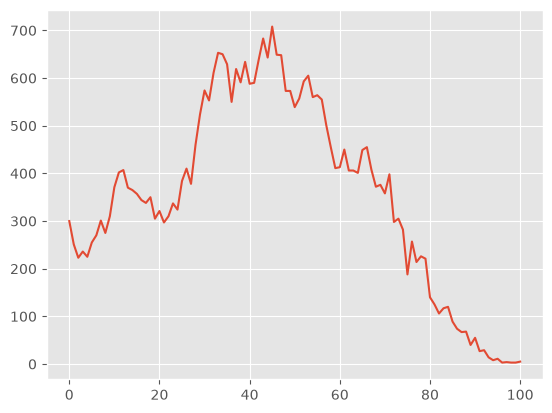

In [16]:
import matplotlib.pyplot as plt

plt.style.use('ggplot')
plt.plot(result)
plt.show()

In [26]:
# pandas 스타일
mask = df.iloc[:,0].astype(str).str.contains('남양주')
row = df.loc[mask].head(1)
# regex=True : 데이터에서 해당 문자를 찾아 대치 , 3,943 가능
# regex=False : 데이터가 정확히 일치할 경우만 대치, ,만 가능
result = row.iloc[:, 3:].replace(',', '', regex=True).astype(int).values.flatten().tolist()
print(len(result))

101


* 성별구분

In [28]:
import pandas as pd

df = pd.read_csv('./data/gender.csv', encoding='cp949')

# 지역 입력
name = input('지역명을 입력하세요: ')
mask = df.iloc[:,0].astype(str).str.contains(name)
row = df.loc[mask].head(1)

male = (row.iloc[:, 3:104]
          .replace(',', '', regex=True)
          .astype(int)
          .values
          .flatten()
          .tolist())

female = (row.iloc[:, -101:]
          .replace(',', '', regex=True)
          .astype(int)
          .values
          .flatten()
          .tolist())

print("남자:", len(male))
print("여자:", len(female))

print("남자:", male)
print("여자:", female)

남자: 101
여자: 101
남자: [151, 121, 106, 126, 115, 140, 138, 153, 139, 162, 200, 195, 216, 165, 150, 176, 178, 162, 174, 156, 171, 158, 143, 154, 155, 175, 187, 152, 188, 218, 266, 254, 261, 293, 299, 301, 261, 293, 294, 303, 307, 285, 313, 350, 305, 336, 308, 326, 264, 276, 254, 274, 284, 311, 275, 276, 270, 248, 213, 210, 199, 217, 203, 200, 197, 219, 234, 193, 181, 165, 164, 182, 127, 135, 127, 79, 121, 120, 119, 111, 69, 61, 53, 48, 69, 41, 32, 28, 27, 12, 14, 9, 4, 7, 4, 3, 0, 0, 0, 1, 0]
여자: [149, 130, 117, 110, 110, 115, 132, 148, 136, 148, 171, 207, 191, 205, 215, 181, 166, 176, 176, 149, 150, 139, 167, 183, 169, 209, 223, 226, 272, 306, 308, 299, 350, 360, 351, 328, 289, 326, 297, 331, 281, 305, 325, 333, 338, 372, 341, 322, 309, 297, 285, 283, 309, 294, 285, 288, 285, 253, 242, 201, 214, 233, 203, 206, 204, 230, 221, 215, 191, 211, 194, 216, 171, 170, 155, 109, 136, 94, 107, 110, 71, 64, 53, 69, 51, 48, 42, 39, 41, 28, 41, 18, 25, 7, 4, 8, 3, 4, 3, 2, 5]


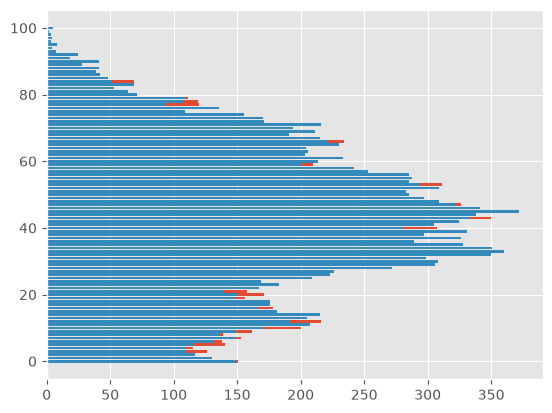

In [29]:
# barh 시각화
import matplotlib.pyplot as plt

plt.barh(range(101), male)
plt.barh(range(101), female)
plt.show()

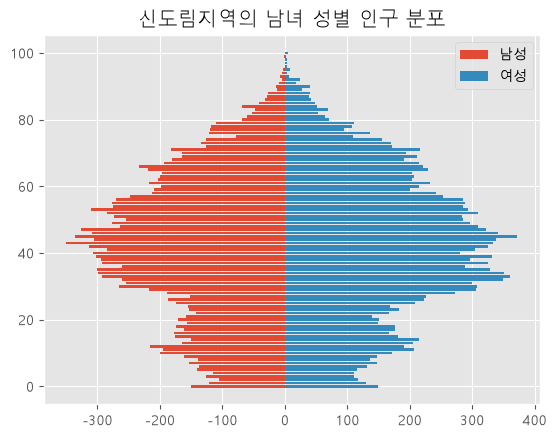

In [33]:
import matplotlib.pyplot as plt

plt.rcParams['font.family'] = 'Malgun Gothic'  # 'AppleGothic'
plt.rcParams['axes.unicode_minus'] = False

plt.title(name + '지역의 남녀 성별 인구 분포')

plt.barh(range(101), [-x for x in male], label = '남성')
plt.barh(range(101), female, label = '여성')

plt.legend()  
plt.show()

In [31]:
# test code
# [-x for x in male]

# result = [-2, -3]
# for x in male:
#     result.append(x * -1)

[-151,
 -121,
 -106,
 -126,
 -115,
 -140,
 -138,
 -153,
 -139,
 -162,
 -200,
 -195,
 -216,
 -165,
 -150,
 -176,
 -178,
 -162,
 -174,
 -156,
 -171,
 -158,
 -143,
 -154,
 -155,
 -175,
 -187,
 -152,
 -188,
 -218,
 -266,
 -254,
 -261,
 -293,
 -299,
 -301,
 -261,
 -293,
 -294,
 -303,
 -307,
 -285,
 -313,
 -350,
 -305,
 -336,
 -308,
 -326,
 -264,
 -276,
 -254,
 -274,
 -284,
 -311,
 -275,
 -276,
 -270,
 -248,
 -213,
 -210,
 -199,
 -217,
 -203,
 -200,
 -197,
 -219,
 -234,
 -193,
 -181,
 -165,
 -164,
 -182,
 -127,
 -135,
 -127,
 -79,
 -121,
 -120,
 -119,
 -111,
 -69,
 -61,
 -53,
 -48,
 -69,
 -41,
 -32,
 -28,
 -27,
 -12,
 -14,
 -9,
 -4,
 -7,
 -4,
 -3,
 0,
 0,
 0,
 -1,
 0]